# Car Price Prediction

Predicting car prices from their specifications using machine learning.

**Pipeline:** data cleaning → EDA → feature engineering → model comparison (Linear Regression, Ridge, Random Forest, Gradient Boosting)

**Best model:** Random Forest, with R² = 0.960 and RMSE ≈ $1,787 on the test set.

# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from category_encoders import OneHotEncoder, BinaryEncoder, OrdinalEncoder
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.feature_selection import chi2, f_classif
from scipy.stats import spearmanr, chi2_contingency
from sklearn.utils import resample
import math
import warnings
warnings.filterwarnings("ignore")

In [2]:
import os
os.getcwd()
os.listdir()

['CarPrice.ipynb', 'CarPrice_Assignment.csv', 'Car_Price.pdf', 'images']

In [3]:
from matplotlib.ticker import FuncFormatter

# ---------- Global style ----------
MAIN   = "#2563EB"   # blue
ACCENT = "#F97316"   # orange
GREY   = "#94A3B8"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.4,
    "figure.dpi": 110,
})

# ---------- Helper: save each figure in high quality ----------
os.makedirs("images", exist_ok=True)
def save_fig(name):
    plt.savefig(f"images/{name}.png", dpi=300, bbox_inches="tight", facecolor="white")

money = FuncFormatter(lambda v, _: f"${v/1000:.0f}k")

# Data Overview

In [4]:
df = pd.read_csv('CarPrice_Assignment.csv')
df.shape

(205, 26)

In [5]:
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 17  fuelsyst

In [7]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [8]:
def data_info(df):
    Names = df.columns
    data_types=[df[col].dtype for col in df.columns]
    top_10_unique_values=[df[col].value_counts().head(10).index.to_list() for col in df.columns]
    nunique_values=[df[col].nunique() for col in df.columns]
    nulls=[df[col].isnull().sum() for col in df.columns]
    percent_of_Nulls= [df[col].isnull().sum()/len(df)*100 for col in df.columns]
    duplicates=df.duplicated().sum()

    info_df=pd.DataFrame({'Name':Names,
                          'Data_Type':data_types,
                          'Top_10_Unique_Values':top_10_unique_values,
                          'Nunique_Values':nunique_values,
                          'Nulls':nulls,
                          'Percent_of_Nulls':percent_of_Nulls,
                          'Duplicates': [duplicates] * len(df.columns)})
    return info_df

In [9]:
df.drop(columns=['car_ID'], inplace=True)

In [10]:
data_info(df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,symboling,int64,"[0, 1, 2, 3, -1, -2]",6,0,0.0,0
1,CarName,str,"[peugeot 504, toyota corona, toyota corolla, s...",147,0,0.0,0
2,fueltype,str,"[gas, diesel]",2,0,0.0,0
3,aspiration,str,"[std, turbo]",2,0,0.0,0
4,doornumber,str,"[four, two]",2,0,0.0,0
5,carbody,str,"[sedan, hatchback, wagon, hardtop, convertible]",5,0,0.0,0
6,drivewheel,str,"[fwd, rwd, 4wd]",3,0,0.0,0
7,enginelocation,str,"[front, rear]",2,0,0.0,0
8,wheelbase,float64,"[94.5, 93.7, 95.7, 96.5, 98.4, 97.3, 98.8, 96....",53,0,0.0,0
9,carlength,float64,"[157.3, 188.8, 186.7, 166.3, 171.7, 177.8, 165...",75,0,0.0,0


Data is Free of Nulls&Duplicates

Symboling-->Categorical column not Numerical


# Analysis and Visualizations to get Information about the data

In [11]:
df.isnull().sum()

symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

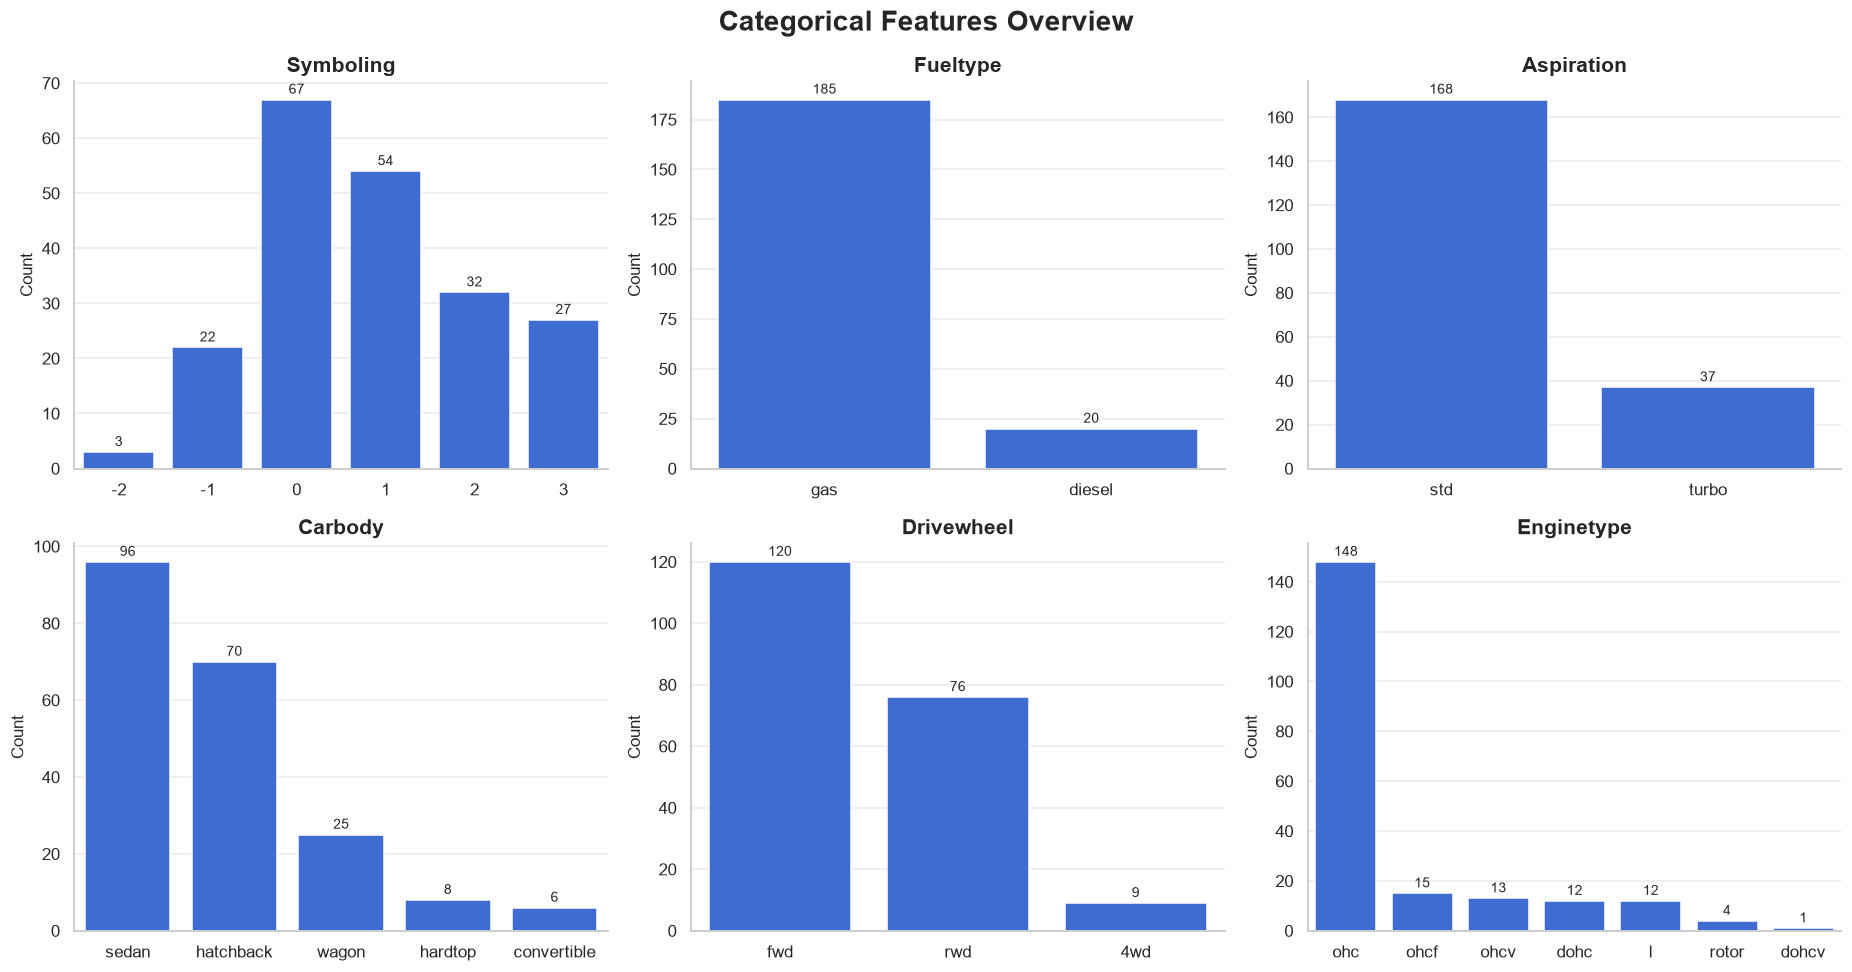

In [12]:
cat_features = ["symboling", "fueltype", "aspiration", "carbody", "drivewheel", "enginetype"]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, cat_features):
    order = sorted(df[col].unique()) if col == "symboling" else df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, color=MAIN, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, padding=2, fontsize=9)
    ax.set_title(col.title())
    ax.set_xlabel("")
    ax.set_ylabel("Count")

fig.suptitle("Categorical Features Overview", fontsize=18, fontweight="bold")
plt.tight_layout()
save_fig("01_categorical_overview")
plt.show()

- Most cars have a symboling value of 0 (average insurance risk).
- Most cars use gas fuel and have a sedan body style.
- OHC is the most common engine type.
- Most cars use standard aspiration; fewer use turbo.
- FWD is the most common drive wheel type.

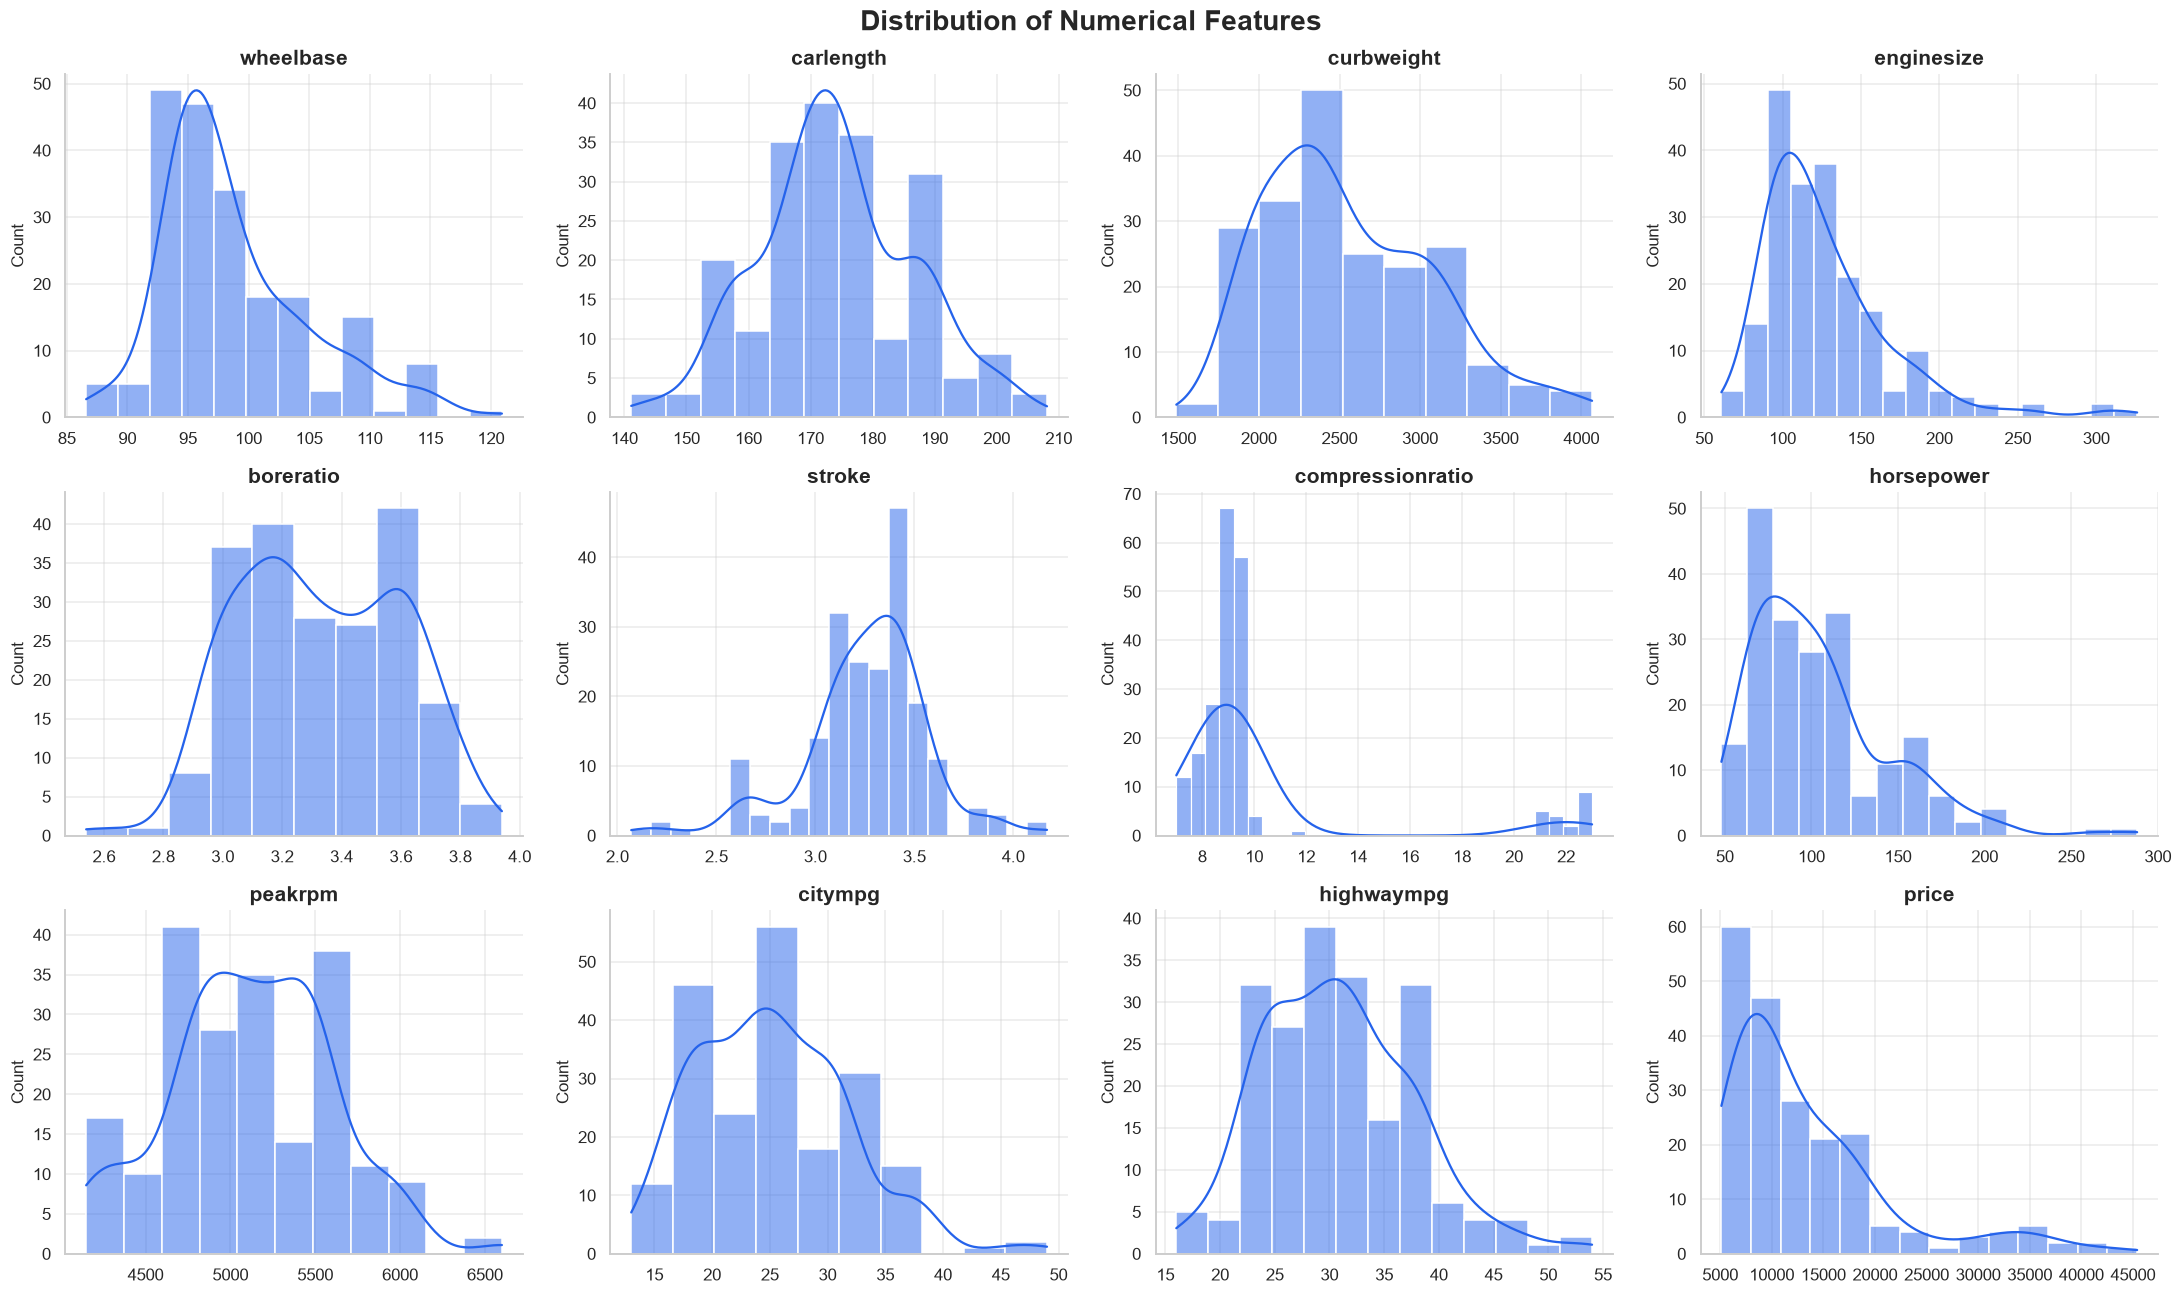

In [13]:
numerical_cols = [
    'wheelbase', 'carlength', 'curbweight',
    'enginesize', 'boreratio', 'stroke',
    'compressionratio', 'horsepower',
    'peakrpm', 'citympg', 'highwaympg',
    'price']
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.flat, numerical_cols):
    sns.histplot(data=df, x=col, kde=True, color=MAIN, edgecolor="white", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Count")

fig.suptitle("Distribution of Numerical Features", fontsize=18, fontweight="bold")
plt.tight_layout()
save_fig("02_numerical_distributions")
plt.show()

- Wheelbase distribution is right-skewed: most vehicles have shorter wheelbases, with fewer cars having larger ones.
- Car length is approximately normally distributed.
- Engine size is right-skewed: most vehicles have smaller engines, with fewer cars having larger ones.

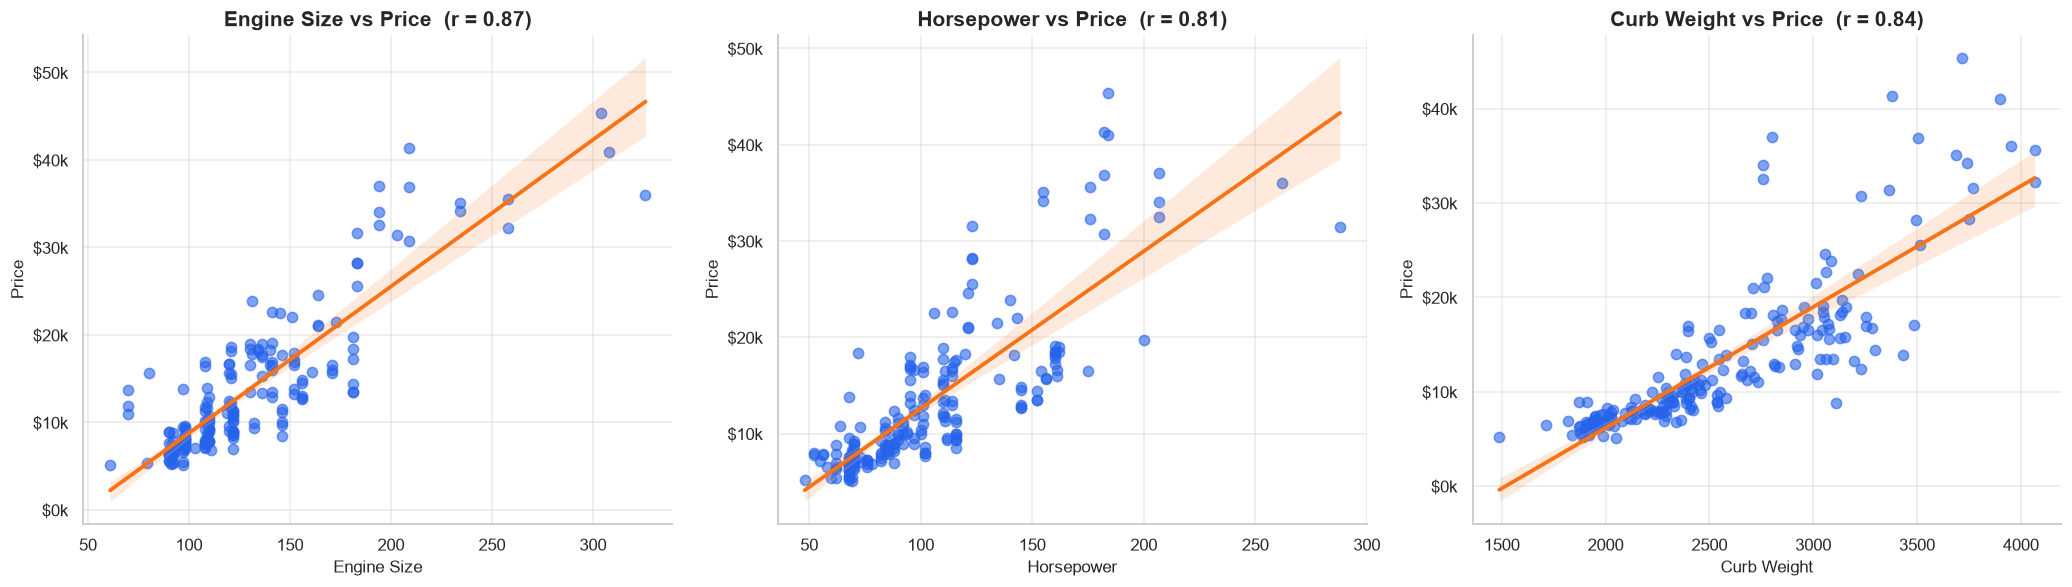

In [14]:
pairs = [("enginesize", "Engine Size"), ("horsepower", "Horsepower"), ("curbweight", "Curb Weight")]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, (col, label) in zip(axes, pairs):
    sns.regplot(data=df, x=col, y="price", ax=ax,
                scatter_kws={"alpha": 0.6, "s": 45, "color": MAIN},
                line_kws={"color": ACCENT, "lw": 2.5})
    r = df[col].corr(df["price"])
    ax.set_title(f"{label} vs Price  (r = {r:.2f})")
    ax.set_xlabel(label)
    ax.set_ylabel("Price")
    ax.yaxis.set_major_formatter(money)

plt.tight_layout()
save_fig("03_price_vs_key_features")
plt.show()

- Engine size and horsepower have a clear positive relationship with price.
- Curb weight has a positive, non-linear relationship with price: heavier cars tend to be more expensive.

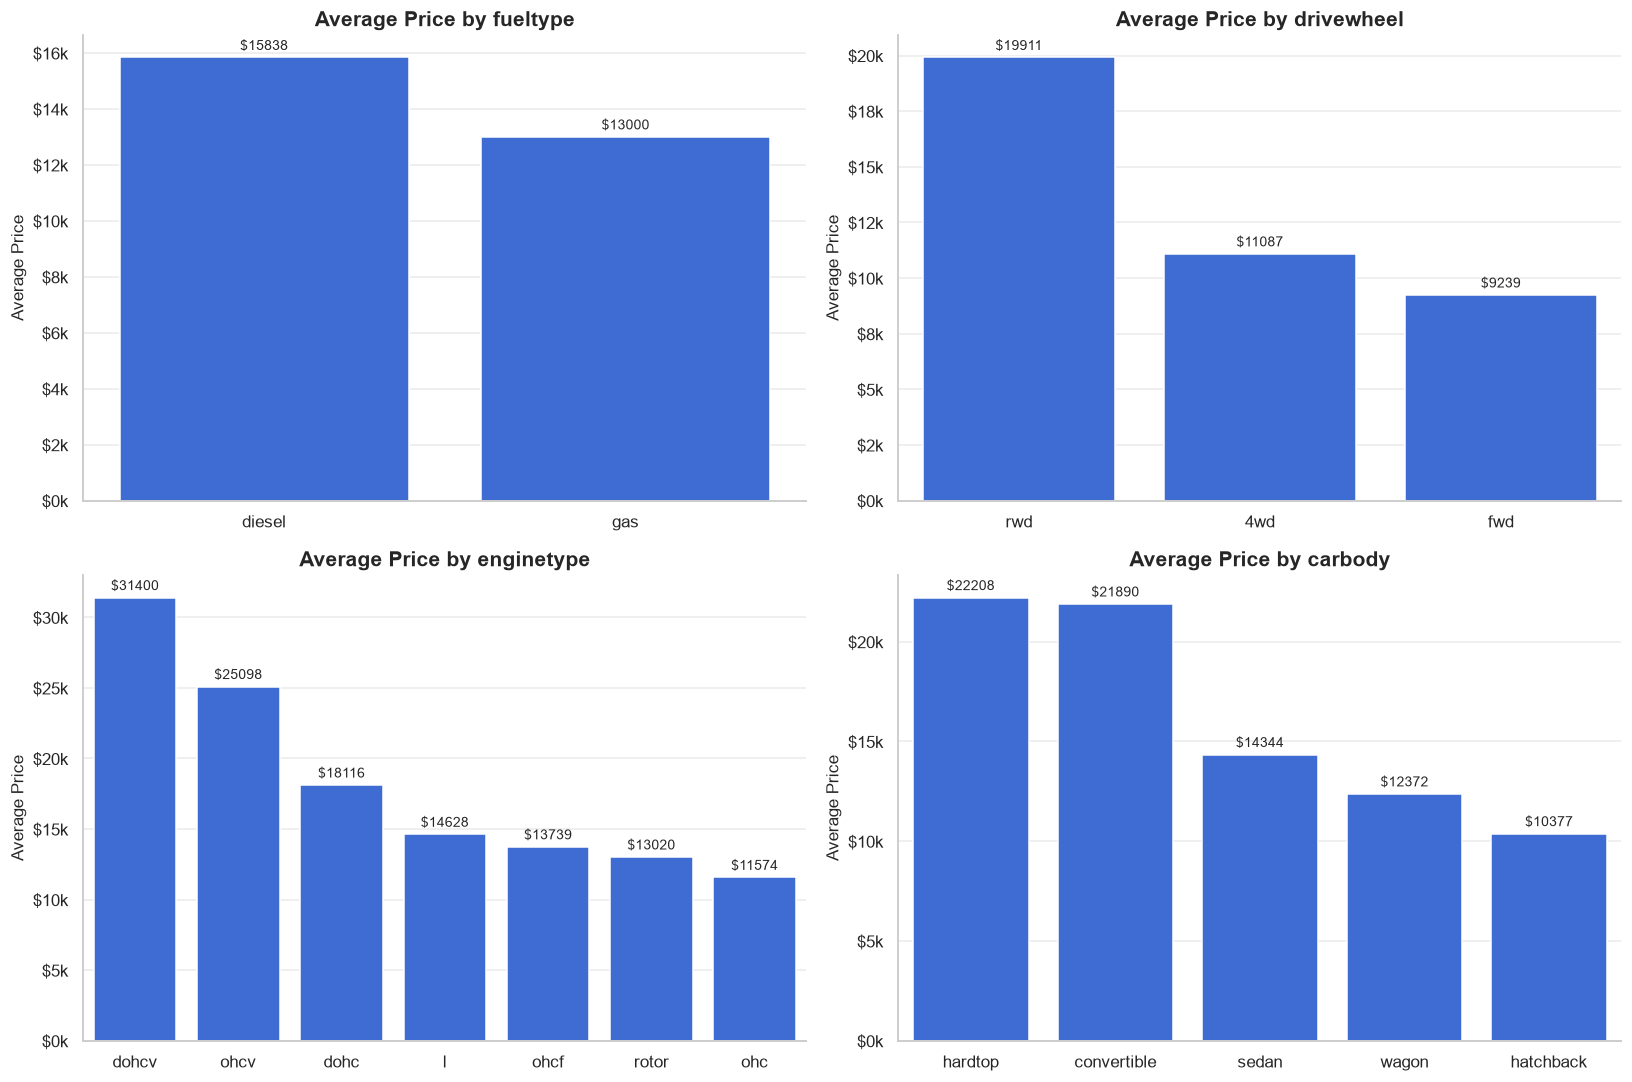

In [15]:
cats = ["fueltype", "drivewheel", "enginetype", "carbody"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.flat, cats):
    order = df.groupby(col)["price"].mean().sort_values(ascending=False).index
    sns.barplot(data=df, x=col, y="price", order=order, color=MAIN, errorbar=None, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="$%.0f", padding=3, fontsize=9)
    ax.set_title(f"Average Price by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Average Price")
    ax.yaxis.set_major_formatter(money)

plt.tight_layout()
save_fig("04_price_by_category")
plt.show()

- Diesel cars have a higher average price than gasoline cars.
- RWD cars have the highest average price among drive wheel types.
- Convertible and hardtop body styles have the highest average price.
- The dohcv engine type has the highest average price (check how many cars it contains before drawing conclusions).

# Preprocessing (Nulls, Duplicates, Outliers)

In [16]:
df.isnull().sum()

symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

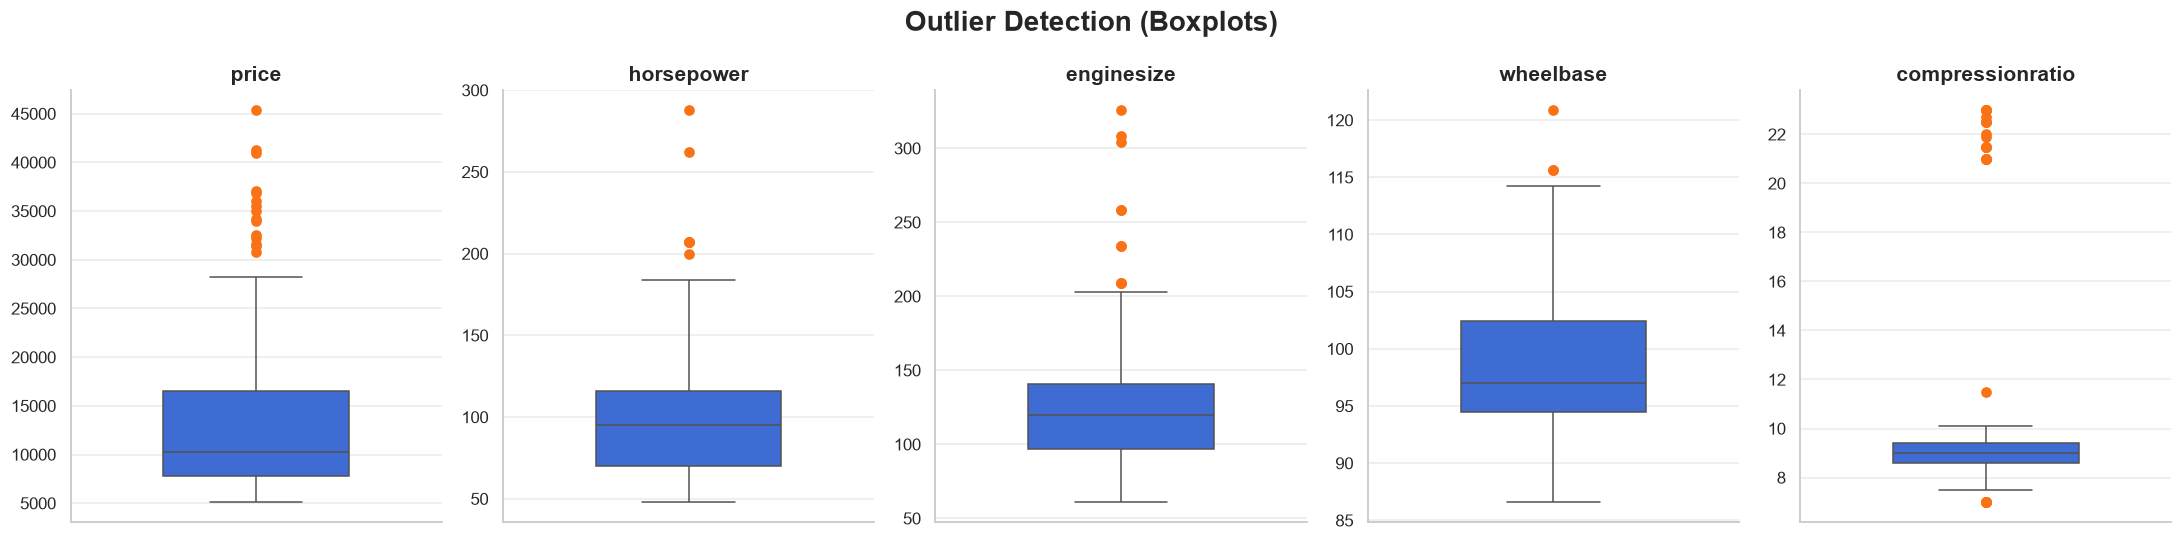

In [18]:
outlier_cols = ["price", "horsepower", "enginesize", "wheelbase", "compressionratio"]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=df[col], color=MAIN, width=0.5, flierprops={"markerfacecolor": ACCENT, "markeredgecolor": ACCENT}, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")

fig.suptitle("Outlier Detection (Boxplots)", fontsize=18, fontweight="bold")
plt.tight_layout()
save_fig("05_outliers")
plt.show()

The price feature contains several high-value outliers

The feature contains a small number of high-value outliers

The enginesize feature contains several high-value outliers. Most cars have engine sizes within a normal range

# Feature Engineering

In [19]:
powerperweight = df['horsepower'] / df['curbweight']
df['power_per_weight'] = powerperweight

In [20]:
average_mpg = (df['citympg'] + df['highwaympg']) / 2
df['average_mpg'] = average_mpg

In [21]:
df["brand"] = df["CarName"].str.split().str[0]

In [22]:
df[["CarName", "brand"]].head()

,CarName,brand
0,alfa-romero giulia,alfa-romero
1,alfa-romero stelvio,alfa-romero
2,alfa-romero Quadrifoglio,alfa-romero
3,audi 100 ls,audi
4,audi 100ls,audi


In [23]:
df.drop("CarName", axis=1, inplace=True)

In [24]:
df["brand"].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'maxda', 'mazda', 'buick', 'mercury',
       'mitsubishi', 'Nissan', 'nissan', 'peugeot', 'plymouth', 'porsche',
       'porcshce', 'renault', 'saab', 'subaru', 'toyota', 'toyouta',
       'vokswagen', 'volkswagen', 'vw', 'volvo'], dtype=object)

In [25]:
df["brand"] = df["brand"].replace({
    "maxda": "mazda",
    "Nissan": "nissan",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen",
    "porcshce": "porsche"
})

In [26]:
df["brand"].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'mazda', 'buick', 'mercury', 'mitsubishi',
       'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab',
       'subaru', 'toyota', 'volkswagen', 'volvo'], dtype=object)

# Split Data

In [27]:
X = df.drop("price", axis=1)
y = df["price"]
X_train,X_test,y_train,y_test = train_test_split(X, y,test_size=0.2,random_state=42)

In [28]:
X_train.select_dtypes(exclude='number').columns

Index(['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel',
       'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem',
       'brand'],
      dtype='str')

In [29]:
for col in X_train.select_dtypes(exclude='number').columns:
    print(col, X_train[col].unique())

fueltype <StringArray>
['diesel', 'gas']
Length: 2, dtype: str
aspiration <StringArray>
['std', 'turbo']
Length: 2, dtype: str
doornumber <StringArray>
['four', 'two']
Length: 2, dtype: str
carbody <StringArray>
['sedan', 'wagon', 'hatchback', 'hardtop', 'convertible']
Length: 5, dtype: str
drivewheel <StringArray>
['rwd', 'fwd', '4wd']
Length: 3, dtype: str
enginelocation <StringArray>
['front', 'rear']
Length: 2, dtype: str
enginetype <StringArray>
['ohc', 'l', 'ohcf', 'dohc', 'rotor', 'ohcv', 'dohcv']
Length: 7, dtype: str
cylindernumber <StringArray>
['four', 'six', 'five', 'two', 'twelve', 'eight']
Length: 6, dtype: str
fuelsystem <StringArray>
['idi', 'mpfi', '2bbl', '1bbl', 'mfi', '4bbl', 'spdi', 'spfi']
Length: 8, dtype: str
brand ['mazda' 'peugeot' 'toyota' 'nissan' 'honda' 'dodge' 'subaru' 'chevrolet'
 'audi' 'porsche' 'mitsubishi' 'mercury' 'bmw' 'saab' 'plymouth' 'volvo'
 'alfa-romero' 'isuzu' 'volkswagen' 'buick' 'jaguar' 'renault']


In [30]:
X_train['doornumber'] = X_train['doornumber'].map({
    'two': 2,
    'four': 4
})

X_test['doornumber'] = X_test['doornumber'].map({
    'two': 2,
    'four': 4
})

## Encoding & Scaling (if needed)

In [31]:
categorical_cols = [
    'brand',
    'fueltype',
    'aspiration',
    'carbody',
    'drivewheel',
    'enginetype',
    'cylindernumber',
    'fuelsystem',
    'enginelocation'
]
categorical_cols = [col for col in categorical_cols if col in df.columns]

In [32]:
existing_cats = [col for col in categorical_cols if col in X_train.columns]
categorical_cols = existing_cats
if existing_cats:
    X_train = pd.get_dummies(X_train, columns=existing_cats, drop_first=True)
X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)

X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

In [33]:
scaler = StandardScaler()
num_cols = X_train.select_dtypes(include='number').columns
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Correlation

In [34]:
corr = df.corr(numeric_only=True)

corr["price"].sort_values(ascending=False)

price               1.000000
enginesize          0.874145
curbweight          0.835305
horsepower          0.808139
carwidth            0.759325
carlength           0.682920
wheelbase           0.577816
boreratio           0.553173
power_per_weight    0.533767
carheight           0.119336
stroke              0.079443
compressionratio    0.067984
symboling          -0.079978
peakrpm            -0.085267
citympg            -0.685751
average_mpg        -0.696835
highwaympg         -0.697599
Name: price, dtype: float64

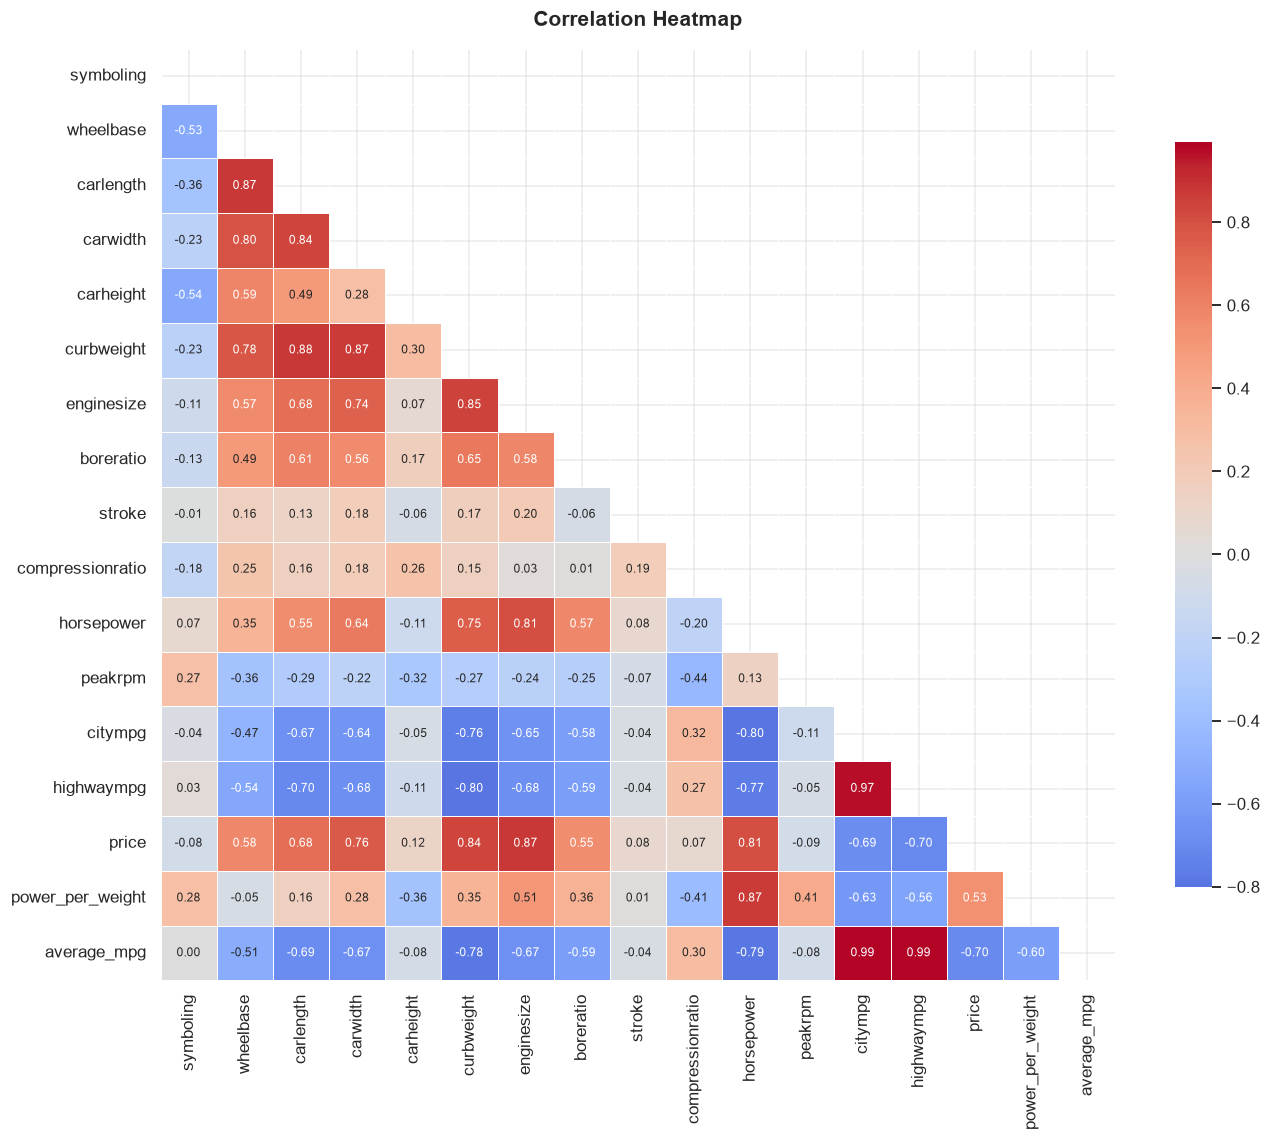

In [35]:
# ---- Correlation heatmap ----
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 11))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, annot_kws={"size": 8}, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap", pad=15)
save_fig("06_correlation_heatmap")
plt.show()

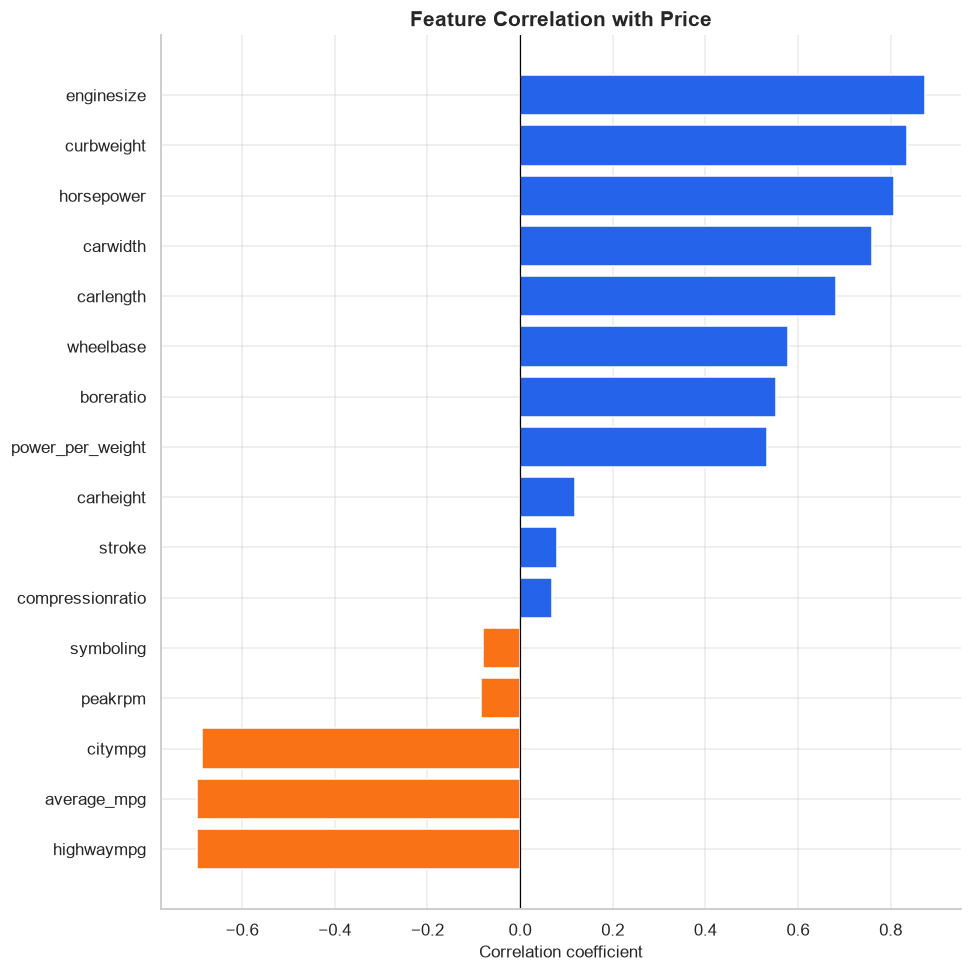

In [36]:
# ---- Correlation with price ----
price_corr = corr["price"].drop("price").sort_values()
colors = [ACCENT if v < 0 else MAIN for v in price_corr]

plt.figure(figsize=(9, 9))
plt.barh(price_corr.index, price_corr.values, color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Feature Correlation with Price")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
save_fig("07_price_correlation")
plt.show()

• Engine size has the strongest positive correlation with price (0.87).

• Curb weight and horsepower are also highly correlated with price.

• Fuel efficiency (City MPG, Highway MPG, and Average MPG) is negatively correlated with price.

• The engineered feature average_mpg appears to be informative for price prediction.

## Model Training

In [37]:
from sklearn.linear_model import LinearRegression

# Create Model
model = LinearRegression()

# Train Model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

## Evaluate Model in Training, Testing

In [38]:
# Import regression evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Mean Absolute Error
mean_absolute_error(y_test, y_pred)

# Mean Squared Error
mean_squared_error(y_test, y_pred)

# Root Mean Squared Error
np.sqrt(mean_squared_error(y_test, y_pred))

# R² Score
r2_score(y_test, y_pred)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 1860.0509253625698
MSE: 6843726.900635222
RMSE: 2616.051777131948
R² Score: 0.9133091167085623


In [39]:
# Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Compare R²
print("Train R²:", r2_score(y_train, y_train_pred))
print("Test R²:", r2_score(y_test, y_test_pred))

Train R²: 0.9776658714973255
Test R²: 0.9133091167085623


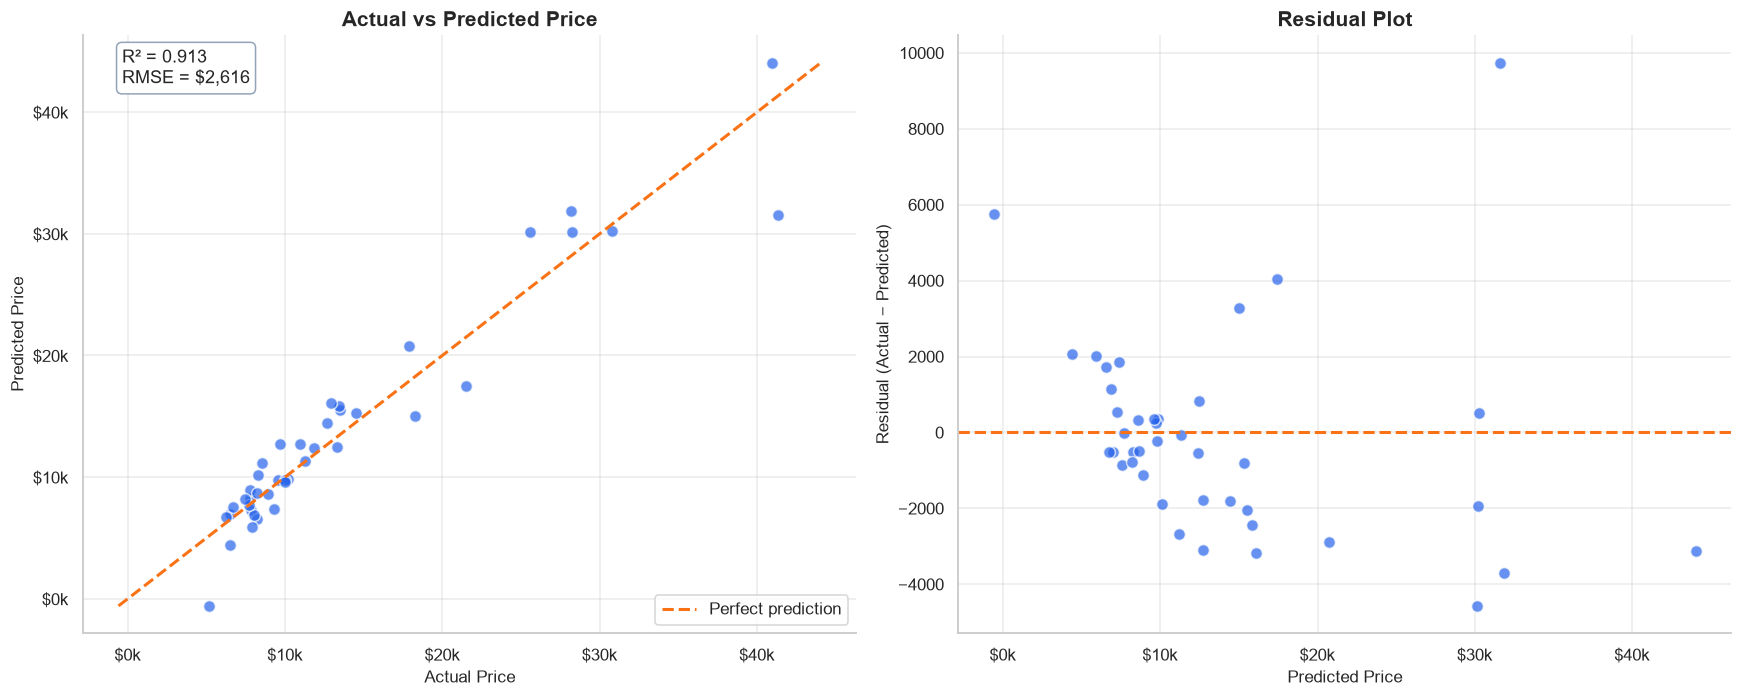

In [40]:
residuals = y_test - y_test_pred
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

axes[0].scatter(y_test, y_test_pred, color=MAIN, alpha=0.7, s=60, edgecolor="white")
axes[0].plot(lims, lims, "--", color=ACCENT, lw=2, label="Perfect prediction")
axes[0].set_title("Actual vs Predicted Price")
axes[0].set_xlabel("Actual Price"); axes[0].set_ylabel("Predicted Price")
axes[0].xaxis.set_major_formatter(money); axes[0].yaxis.set_major_formatter(money)
axes[0].text(0.05, 0.92, f"R² = {r2_score(y_test, y_test_pred):.3f}\nRMSE = ${np.sqrt(mean_squared_error(y_test, y_test_pred)):,.0f}",
             transform=axes[0].transAxes, fontsize=12, bbox=dict(boxstyle="round", fc="white", ec=GREY))
axes[0].legend(loc="lower right")

axes[1].scatter(y_test_pred, residuals, color=MAIN, alpha=0.7, s=60, edgecolor="white")
axes[1].axhline(0, color=ACCENT, ls="--", lw=2)
axes[1].set_title("Residual Plot")
axes[1].set_xlabel("Predicted Price"); axes[1].set_ylabel("Residual (Actual − Predicted)")
axes[1].xaxis.set_major_formatter(money)

plt.tight_layout()
save_fig("08_actual_vs_predicted")
plt.show()

In [41]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    results.append({
        "Model": name,
        "Train R²": r2_score(y_train, m.predict(X_train)),
        "Test R²": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    })

results_df = pd.DataFrame(results).sort_values("Test R²", ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,Train R²,Test R²,MAE,RMSE
0,Random Forest,0.986,0.960,1247.003,1786.890
1,Gradient Boosting,0.994,0.933,1647.046,2303.850
2,Linear Regression,0.978,0.913,1860.051,2616.052
3,Ridge,0.966,0.905,1899.377,2737.582


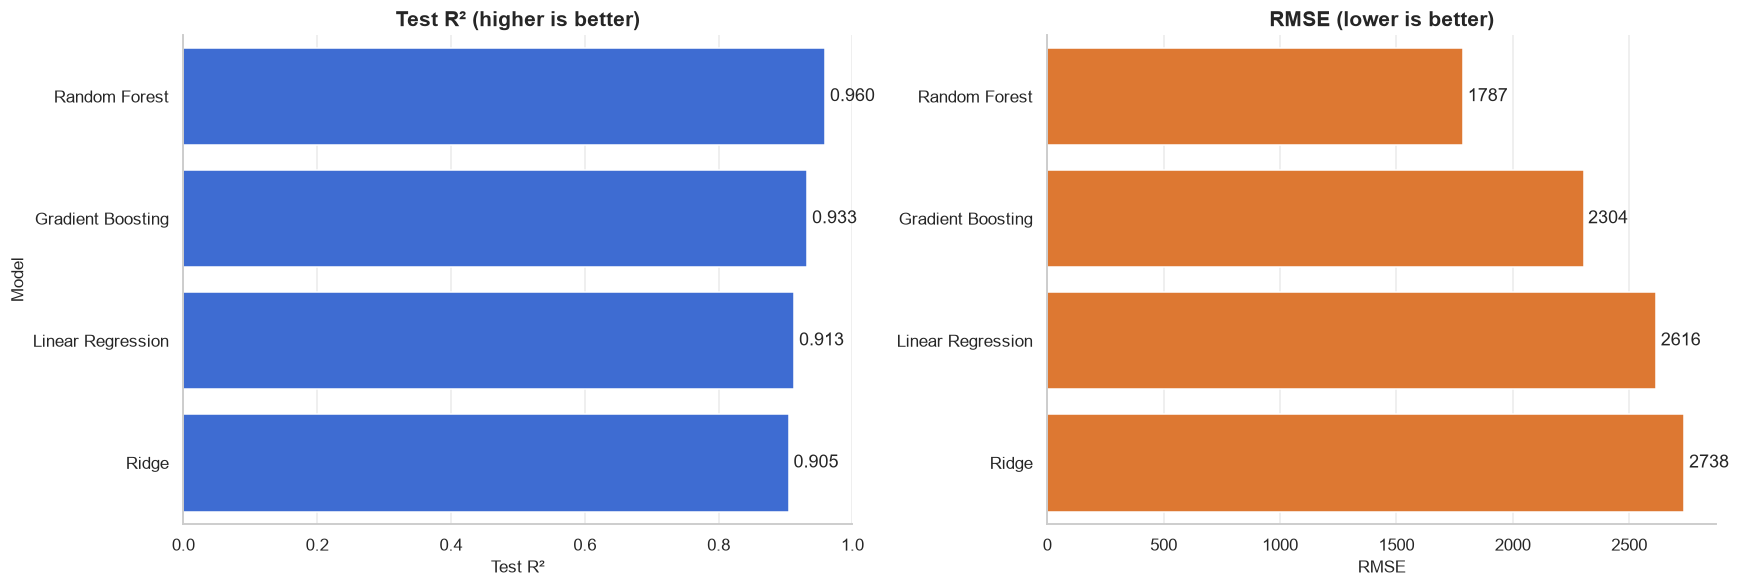

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.barplot(data=results_df, y="Model", x="Test R²", color=MAIN, ax=axes[0])
axes[0].set_title("Test R² (higher is better)")
axes[0].set_xlim(0, 1)
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.3f", padding=3)

sns.barplot(data=results_df, y="Model", x="RMSE", color=ACCENT, ax=axes[1])
axes[1].set_title("RMSE (lower is better)")
axes[1].set_ylabel("")
for c in axes[1].containers: axes[1].bar_label(c, fmt="%.0f", padding=3)

plt.tight_layout()
save_fig("09_model_comparison")
plt.show()

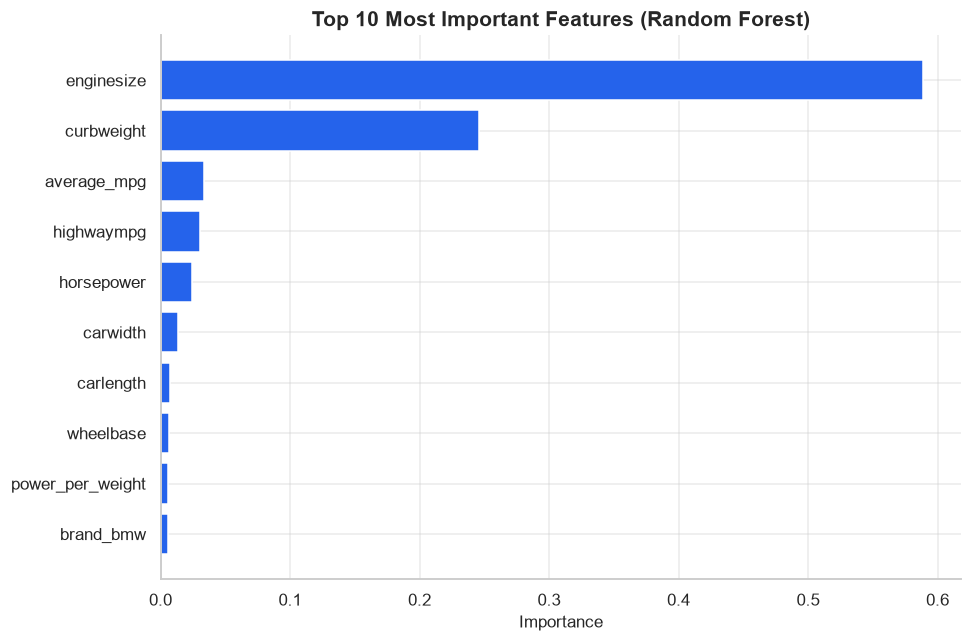

In [43]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values().tail(10)

plt.figure(figsize=(9, 6))
plt.barh(importances.index, importances.values, color=MAIN)
plt.title("Top 10 Most Important Features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
save_fig("10_feature_importance")
plt.show()

## Any Notes About the Evaluation and the task overall

## Evaluation Notes

Four regression models were compared on the held-out test set:

| Model | Train R² | Test R² | MAE | RMSE |
|---|---|---|---|---|
| Random Forest | 0.986 | 0.960 | 1,247 | 1,787 |
| Gradient Boosting | 0.994 | 0.933 | 1,647 | 2,304 |
| Linear Regression | 0.978 | 0.913 | 1,860 | 2,616 |
| Ridge | 0.966 | 0.905 | 1,899 | 2,738 |

- **Random Forest performed best**, reducing the average error by about $830 (RMSE) compared with the Linear Regression baseline. Tree-based models likely benefit from capturing non-linear relationships, such as curb weight vs. price.
- Random Forest has a small train/test gap (0.986 vs 0.960), while Gradient Boosting overfits more (0.994 vs 0.933).
- Ridge did not improve on plain Linear Regression.
- **Limitations:** the dataset is small (about 200 cars), so the test set is small and results may vary with a different split. Next steps: cross-validation and hyperparameter tuning.